# SEMEFO-DF: Análisis

Primer análisis de datos del SEMEFO 1974

## Notas
* Limpieza adicional:
    * Guardar valores iniciales
    * En rango de edad replace('(5, 10]', '(05, 10]'
    * Los fetos tienen edad nan
    * Unir PROCEDENCIA con AVERIGUACION PREVIA para completar ids

* Centrar el análisis en cadaveres con nombre o desconocido
    * Ignorar Fetos, Miembros y R nacidos


In [1]:
from warnings import warn
import pandas as pd
from numpy import nan
import seaborn as sns
import matplotlib.pyplot as plt
from helper_pandas import profile_minimal, profile_by_categorical_column, multicolumn_value_counts_with_filter
from helper_pandas import join_strings_with_nans


In [2]:
file_review = "data_clean/SEMEFO_BitacoraOnomastica_1974_review.csv"
df = pd.read_csv(file_review)

df['FECHA'] = pd.to_datetime(df['FECHA'])
df.loc[df['TIPOS DE RESTOS']=='Feto','EDAD'] = nan
df['RANGO EDAD'] = df['RANGO EDAD'].replace('(5, 10]', '(05, 10]')
df['AVERIGUACION PREVIA CON PROCEDENCIA'] = df[['PROCEDENCIA MP Y DEL','AVERIGUACION PREVIA']].apply(join_strings_with_nans, axis=1)

df.dtypes

NOMBRE COMPLETO                                object
APELLIDO PATERNO                               object
APELLIDO MATERNO                               object
NOMBRES PROPIOS                                object
PROCEDENCIA MP Y DEL                           object
AVERIGUACION PREVIA                            object
EXP SEMEFO                                     object
FECHA                                  datetime64[ns]
SEMANA                                        float64
DIA SEMANA                                     object
TIPOS DE RESTOS                                object
EDAD                                          float64
RANGO EDAD                                     object
SEXO                                           object
DIAGNOSTICO                                    object
OBSERVACIONES CAPTURISTA                       object
TRANSCRIPCION INCIERTA                           bool
DESCONOCIDO                                      bool
PAGINA PDF                  

## Tipo de resto y nombre

In [4]:
file_profi = "profiles/SEMEFO_1974/SEMEFO_1974_review.html"
title = 'Bitácoras onomásticas SEMEFO 1974'
profile_minimal(df, file_profi, title)
profile_by_categorical_column(df, file_profi, 'TIPOS DE RESTOS', title=title)
profile_by_categorical_column(df, file_profi, 'NOMBRE COMPLETO', title=title, low_freq_label='CON NOMBRE')

Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_TIPOS DE RESTOS_Cadáver.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_TIPOS DE RESTOS_Feto.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_TIPOS DE RESTOS_Miembro.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_NOMBRE COMPLETO_DESCONOCIDO.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_NOMBRE COMPLETO_FETO.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_NOMBRE COMPLETO_R NACIDO.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_NOMBRE COMPLETO_CON NOMBRE.html file alredy exists


## Edad y sexo

In [5]:
counts = multicolumn_value_counts_with_filter(df, ['RANGO EDAD','DIAGNOSTICO'], min_freq=15)
print( counts['Frequency'].sum()/df.shape[0]*100 )
counts

34.71132042560614


,RANGO EDAD,DIAGNOSTICO,Frequency
0,"(-1, 0]",BN,44
1,"(-1, 0]",TCE,24
2,"(-1, 0]",AOVA,18
3,"(0, 5]",TCE,56
4,"(0, 5]",TM,44
5,"(0, 5]",ASB,20
6,"(0, 5]",Quemaduras,20
7,"(0, 5]",TCT,16
8,"(05, 10]",TCE,39
9,"(05, 10]",TM,36


In [5]:
profile_by_categorical_column(df, file_profi, 'SEXO', title=title)

target_col = 'EDAD'
k=0 
file_profi_ = file_profi.replace('.html', '_{}_{}.html'.format(target_col, k))
title_ = '{}/n{}: {}'.format(title, target_col, k)
profile_minimal(df[df['EDAD']==0], file_profi_, title_)
k = 'mas0'
file_profi_ = file_profi.replace('.html', '_{}_{}.html'.format(target_col, k))
title_ = '{}/n{}: {}'.format(title, target_col, k)
profile_minimal(df[df['EDAD']>0], file_profi_, title_)

Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_SEXO_Masculino.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_SEXO_Femenino.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_SEXO_low frequency.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_EDAD_0.html file alredy exists
Ignoring profiles/SEMEFO_1974/SEMEFO_1974_review_EDAD_mas0.html file alredy exists


# Registros de interes (cadaveres de más de un año)

In [6]:
df_int = df[(df['TIPOS DE RESTOS']=='Cadáver') & (df['EDAD']!=0)]
df_int.shape

(5128, 21)

## Datos faltantes

Faltantes por columna (se ignoran faltantes de nombre desconocido)

In [7]:
col_ignore = ['SEMANA', 'DIA SEMANA', 'OBSERVACIONES CAPTURISTA',
              'TRANSCRIPCION INCIERTA', 'DESCONOCIDO', 'PAGINA PDF', 'FOJA']
df_int.loc[(df_int['NOMBRE COMPLETO']=='DESCONOCIDO'),['APELLIDO PATERNO','APELLIDO MATERNO','NOMBRES PROPIOS']] = ''
df_int.isna().sum()

NOMBRE COMPLETO                           0
APELLIDO PATERNO                          2
APELLIDO MATERNO                        105
NOMBRES PROPIOS                          81
PROCEDENCIA MP Y DEL                      5
AVERIGUACION PREVIA                       5
EXP SEMEFO                               14
FECHA                                    18
SEMANA                                   18
DIA SEMANA                               18
TIPOS DE RESTOS                           0
EDAD                                    280
RANGO EDAD                              280
SEXO                                      9
DIAGNOSTICO                              35
OBSERVACIONES CAPTURISTA               4216
TRANSCRIPCION INCIERTA                    0
DESCONOCIDO                               0
PAGINA PDF                                0
FOJA                                      0
AVERIGUACION PREVIA CON PROCEDENCIA       4
dtype: int64

Faltantes por fila (se ignoran faltantes de nombre desconocido)

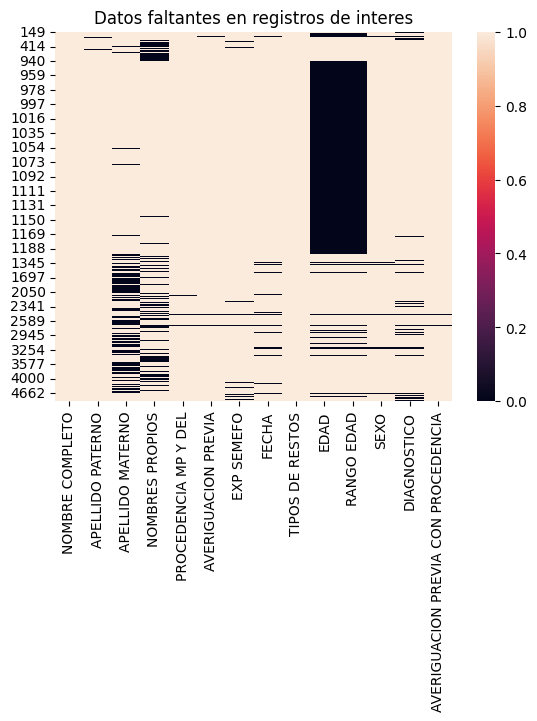

/tmp/ipykernel_3202/1601840572.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_missing['TOTAL FALTANTES'] = df_missing.drop(col_ignore, axis=1).isna().sum(axis=1)


In [8]:
df_missing = df_int[df_int.drop(col_ignore, axis=1).isna().sum(axis=1)>0]

ax = plt.axes()
sns.heatmap( df_missing.drop(col_ignore, axis=1).notna(), )
ax.set_title("Datos faltantes en registros de interes")
plt.show()

df_missing['TOTAL FALTANTES'] = df_missing.drop(col_ignore, axis=1).isna().sum(axis=1)
df_missing.to_csv(file_review.replace('.csv','_missing.csv'))

In [9]:
df_missing.drop(col_ignore, axis=1).sort_values(by='TOTAL FALTANTES', ascending=False).head(10)

,NOMBRE COMPLETO,APELLIDO PATERNO,APELLIDO MATERNO,NOMBRES PROPIOS,PROCEDENCIA MP Y DEL,AVERIGUACION PREVIA,EXP SEMEFO,FECHA,TIPOS DE RESTOS,EDAD,RANGO EDAD,SEXO,DIAGNOSTICO,AVERIGUACION PREVIA CON PROCEDENCIA,TOTAL FALTANTES
2688,MARTINEZ MARTINEZ,MARTINEZ,MARTINEZ,NaN,NaN,NaN,NaN,NaT,Cadáver,NaN,NaN,Masculino,NaN,NaN,9
2487,LOPEZ MEDRANA V MANUEL REP,LOPEZ,MEDRANA,V MANUEL REP,NaN,NaN,NaN,NaT,Cadáver,NaN,NaN,NaN,NaN,NaN,9
3254,ORTIZ GUTIERREZ GUSTAVO,ORTIZ,GUTIERREZ,GUSTAVO,NaN,NaN,NaN,NaT,Cadáver,NaN,NaN,NaN,NaN,NaN,9
2352,LARES AVILA RAFEL,LARES,AVILA,RAFEL,NaN,NaN,6329/73,NaT,Cadáver,NaN,NaN,Masculino,NaN,NaN,7
195,ALVAREZ CHAVEZ JUNIOR,ALVAREZ,CHAVEZ,JUNIOR,HV,NaN,3981,NaT,Cadáver,NaN,NaN,NaN,NaN,HV,6
3168,MATEOS JIMENEZ ALBERTO M,MATEOS,JIMENEZ,ALBERTO M,CR,1440,6418,NaT,Cadáver,NaN,NaN,NaN,NaN,CR 1440,5
4662,DESCONOCIDO,,,,11A,351,1892,NaT,Cadáver,NaN,NaN,NaN,NaN,11A 351,5
3521,PLACENTA,PLACENTA,NaN,NaN,9A,1600,4194,1974-09-03,Cadáver,NaN,NaN,NaN,Desecho Obstétrico,9A 1600,5
1354,FUENTES BOBEDILLA AURELIO,FUENTES,BOBEDILLA,AURELIO,CM,1906,5054,NaT,Cadáver,NaN,NaN,NaN,NaN,CM 1906,5
3179,MIRANDA RODIA MARIA,MIRANDA,RODIA,MARIA,HRL,1368,5914,NaT,Cadáver,NaN,NaN,NaN,NaN,HRL 1368,5


## Procedencia y diagnóstico

In [10]:
counts = multicolumn_value_counts_with_filter(df_int, ['PROCEDENCIA MP Y DEL', 'DIAGNOSTICO'], min_freq=15)
print( counts['Frequency'].sum()/df_int.shape[0]*100 )
counts

27.281591263650544


,PROCEDENCIA MP Y DEL,DIAGNOSTICO,Frequency
0,10A,TCE,19
1,10A,TM,18
2,11A,TM,20
3,13A,TM,46
4,13A,TCE,15
5,14A,TM,37
6,15A,TM,23
7,18A,TM,45
8,19A,TM,19
9,1A,TM,34


In [71]:
counts.columns

Index(['NOMBRE COMPLETO', 'APELLIDO PATERNO', 'APELLIDO MATERNO',
       'NOMBRES PROPIOS', 'PROCEDENCIA MP Y DEL', 'AVERIGUACION PREVIA',
       'EXP SEMEFO', 'FECHA', 'SEMANA', 'DIA SEMANA', 'TIPOS DE RESTOS',
       'EDAD', 'RANGO EDAD', 'SEXO', 'DIAGNOSTICO', 'OBSERVACIONES CAPTURISTA',
       'TRANSCRIPCION INCIERTA', 'DESCONOCIDO', 'PAGINA PDF', 'FOJA',
       'AVERIGUACION PREVIA CON PROCEDENCIA'],
      dtype='object')

In [107]:
counts = multicolumn_value_counts_with_filter(df_int[df_int['SEXO']=='Masculino'], ['RANGO EDAD', 'DIAGNOSTICO', ], min_freq=14)
print( counts['Frequency'].sum()/df_int.shape[0]*100 )
counts

28.39313572542902


,RANGO EDAD,DIAGNOSTICO,Frequency
0,"(0, 5]",TCE,35
1,"(0, 5]",TM,28
2,"(0, 5]",Quemaduras,16
3,"(0, 5]",ASB,14
4,"(05, 10]",TCE,27
5,"(05, 10]",TM,24
6,"(10, 15]",TCE,26
7,"(10, 15]",TM,26
8,"(15, 20]",TM,53
9,"(15, 20]",TCE,45


In [106]:
counts = multicolumn_value_counts_with_filter(df_int[df_int['SEXO']=='Femenino'], ['RANGO EDAD', 'DIAGNOSTICO', ], min_freq=4)
print( counts['Frequency'].sum()/df_int.shape[0]*100 )
counts

7.800312012480499


,RANGO EDAD,DIAGNOSTICO,Frequency
0,"(0, 5]",TCE,21
1,"(0, 5]",TM,16
2,"(0, 5]",TCT,8
3,"(0, 5]",Dispensan,6
4,"(0, 5]",ASB,6
5,"(0, 5]",TTA,6
6,"(0, 5]",BN,5
7,"(0, 5]",Quemaduras+BN,5
8,"(0, 5]",Quemaduras,4
9,"(05, 10]",TCE,12


In [85]:
counts = df_int[df_int['DIAGNOSTICO'].str.contains('HPA')==True]
counts = multicolumn_value_counts_with_filter(counts, ['PROCEDENCIA MP Y DEL', 'DIAGNOSTICO'])
counts.groupby('PROCEDENCIA MP Y DEL').sum().sort_values(by='Frequency', ascending=False)
#counts[['PROCEDENCIA MP Y DEL', 'DIAGNOSTICO']].value_counts().head(50)

,Frequency
PROCEDENCIA MP Y DEL,
CR,39
HB,28
HX,23
14A,21
CM,19
13A,18
15A,17
HV,17
24A,15


## Averiguaciones previas

In [27]:
df_int['AVERIGUACION PREVIA CON PROCEDENCIA'].value_counts()

1    4361
2     330
3      16
4       6
5       3
9       1
7       1
Name: AVERIGUACION PREVIA CON PROCEDENCIA, dtype: int64

In [12]:
df_int[df_int['AVERIGUACION PREVIA CON PROCEDENCIA']=='9A 866']

,NOMBRE COMPLETO,APELLIDO PATERNO,APELLIDO MATERNO,NOMBRES PROPIOS,PROCEDENCIA MP Y DEL,AVERIGUACION PREVIA,EXP SEMEFO,FECHA,SEMANA,DIA SEMANA,...,EDAD,RANGO EDAD,SEXO,DIAGNOSTICO,OBSERVACIONES CAPTURISTA,TRANSCRIPCION INCIERTA,DESCONOCIDO,PAGINA PDF,FOJA,AVERIGUACION PREVIA CON PROCEDENCIA
685,CAMACHO GALVAN GEORGINA,CAMACHO,GALVAN,GEORGINA,9A,866,2332,1974-05-15,20.0,Miércoles,...,30.0,"(25, 30]",Femenino,Quemaduras,NaN,False,False,13,23,9A 866
686,CAMACHO GALVAN J MANUEL,CAMACHO,GALVAN,J MANUEL,9A,866,2333,1974-05-15,20.0,Miércoles,...,14.0,"(10, 15]",Masculino,Quemaduras,NaN,True,False,13,23,9A 866
687,CAMACHO DE JESUS ESTHER,CAMACHO,DE JESUS,ESTHER,9A,866,2335,1974-05-14,20.0,Martes,...,22.0,"(20, 25]",Femenino,Quemaduras,NaN,False,False,13,23,9A 866
688,CAMACHO GALVAN JOSE,CAMACHO,GALVAN,JOSE,9A,866,2337,1974-05-15,20.0,Miércoles,...,60.0,"(55, 60]",Masculino,Quemaduras,NaN,False,False,13,23,9A 866
689,CAMACHO GALVAN MARIA DEL C,CAMACHO,GALVAN,MARIA DEL C,9A,866,2339,1974-05-16,20.0,Jueves,...,6.0,"(05, 10]",Femenino,Quemaduras,NaN,True,False,13,23,9A 866
1612,GALVAN JUAREZ SOLIDAD,GALVAN,JUAREZ,SOLIDAD,9A,866,2338,1974-05-15,20.0,Miércoles,...,46.0,"(45, 50]",Masculino,Quemaduras,NaN,False,False,31,52,9A 866
2441,LESCAS CAMACHO RODRIGO,LESCAS,CAMACHO,RODRIGO,9A,866,2331,1974-05-15,20.0,Miércoles,...,2.0,"(0, 5]",Masculino,Quemaduras,NaN,False,False,48,78,9A 866
2442,LESCAS CAMACHO RENE,LESCAS,CAMACHO,RENE,9A,866,2336,1974-05-15,20.0,Miércoles,...,9.0,"(05, 10]",Masculino,Quemaduras,NaN,False,False,48,78,9A 866
2814,MENDOZA MORA JUAN,MENDOZA,MORA,JUAN,9A,866,2330,1974-05-15,20.0,Miércoles,...,40.0,"(35, 40]",Masculino,Quemaduras,NaN,False,False,55,89,9A 866


In [56]:
for i, s in df['SEXO'].value_counts().items():
    print(i,s)

Masculino 4430
Femenino 1278


In [86]:
def count_unique(s):
    data = s.value_counts()

df_int.groupby('AVERIGUACION PREVIA CON PROCEDENCIA').agg(
    TAMAÑO = pd.NamedAgg(column = 'NOMBRE COMPLETO', aggfunc='size'),
    #FECHA = pd.NamedAgg(column = 'FECHA', aggfunc=pd.unique),
    EXP_SEMEFO = pd.NamedAgg(column = 'EXP SEMEFO', aggfunc=pd.unique),
    #EDAD = pd.NamedAgg(column = 'EDAD', aggfunc=pd.unique),
    SEXO = pd.NamedAgg(column = 'SEXO', aggfunc=pd.unique),
    DIAGNOSTICO = pd.NamedAgg(column = 'DIAGNOSTICO', aggfunc=pd.unique ),
    NOMBRES = pd.NamedAgg(column = 'NOMBRE COMPLETO', aggfunc=lambda s: ' \n'.join(s)),
    ).sort_values(by='TAMAÑO', ascending=False).head(11)

,TAMAÑO,EXP_SEMEFO,SEXO,DIAGNOSTICO,NOMBRES
AVERIGUACION PREVIA CON PROCEDENCIA,,,,,
9A 866,9,"[2332, 2333, 2335, 2337, 2339, 2338, 2331, 233...","[Femenino, Masculino]",[Quemaduras],CAMACHO GALVAN GEORGINA \nCAMACHO GALVAN J MAN...
PGR 746,7,"[791, 792, 793, 794, 795]","[Masculino, Femenino]","[HPPAFP, HPAFPC, HsPPAEP, HsPAFPsTA, HsPAPPTyA]",DESCONOCIDO \nDESCONOCIDO \nDESCONOCIDO \nDESC...
5A 765,5,"[3803, 3269, 3267, 3268, 3258]","[Femenino, Masculino]","[BN+ENT, TM, TCT, TCT+AOVA, TCTA]",CORTES JUANA LEONOR \nESPINOZA MONTES PETRA \n...
CR 720,5,"[3240, 3560, 3585, 3567, 3570]","[Masculino, Femenino]","[TCE+N, TM, TCE, TCT]",CRUZ SALAS LEONARDO \nCONTRERAS SANTOS FAUSTIN...
27A 727,5,"[4690, 4692, 4693, 4694, 4691]","[Masculino, Femenino]","[Quemaduras, AS]",AVILA ALVAREZ MIGUEL \nAMAYA DE CABANOS EMMA \...
23A 343,4,"[3038, 3039, 3070, 3040]","[Femenino, Masculino]","[TM, TCE]",LAUTRE BASSET NICOLE IVONE \nLAURENT BOSSET OL...
HV 435,4,"[955, 2105, 2091, 2104]","[Masculino, Femenino]","[TCE, nan, TCT, TCTA]",DELGADO REYES ARISTEO \nFUENTES RIVERA ERNESTI...
23A 302,4,"[1422, 1513, 2815, 2816]","[Femenino, Masculino]","[Quemaduras, HPAFPA, HsPPAFPT]",DE LA ROSA OLMOS MARIA LOURDES \nDOMINGUEZ MAR...
23A 445,4,"[2150, 3672, 3671, 3673]",[Masculino],"[TCT, Electrofulguración, Electrocución]",DOMINGUEZ ROSAS JESUS \nFLORES MERLO JUAN \nNI...


In [91]:
df[df['AVERIGUACION PREVIA CON PROCEDENCIA']=='23A 445']

,NOMBRE COMPLETO,APELLIDO PATERNO,APELLIDO MATERNO,NOMBRES PROPIOS,PROCEDENCIA MP Y DEL,AVERIGUACION PREVIA,EXP SEMEFO,FECHA,SEMANA,DIA SEMANA,...,EDAD,RANGO EDAD,SEXO,DIAGNOSTICO,OBSERVACIONES CAPTURISTA,TRANSCRIPCION INCIERTA,DESCONOCIDO,PAGINA PDF,FOJA,AVERIGUACION PREVIA CON PROCEDENCIA
1071,DOMINGUEZ ROSAS JESUS,DOMINGUEZ,ROSAS,JESUS,23A,445,2150,1974-03-04,10.0,Lunes,...,NaN,NaN,Masculino,TCT,NaN,False,False,20 reverso,35,23A 445
1326,FLORES MERLO JUAN,FLORES,MERLO,JUAN,23A,445,3672,1974-08-02,31.0,Viernes,...,52.0,"(50, 55]",Masculino,Electrofulguración,NaN,False,False,26,43,23A 445
3221,NIETO MARTINEZ ISRAEL,NIETO,MARTINEZ,ISRAEL,23A,445,3671,1974-08-02,31.0,Viernes,...,15.0,"(10, 15]",Masculino,Electrocución,NaN,False,False,62 reverso,101,23A 445
3937,RAMIREZ PORTILLO SILVESTRE,RAMIREZ,PORTILLO,SILVESTRE,23A,445,3673,1974-08-02,31.0,Viernes,...,18.0,"(15, 20]",Masculino,Electrofulguración,NaN,False,False,78,122,23A 445


## Varios

In [ ]:
df[(df['PROCEDENCIA MP Y DEL']=='PGR') & (df['AVERIGUACION PREVIA']=='746')]

In [ ]:
df[['PROCEDENCIA MP Y DEL','AVERIGUACION PREVIA']].value_counts().head(50)

In [ ]:
df[df['PROCEDENCIA MP Y DEL']=='SC']

In [ ]:
from helper_pandas import groupby_column_values_and_separate_low_freq
procedencia_low = groupby_column_values_and_separate_low_freq(df, 'PROCEDENCIA MP Y DEL', min_rows=15)
procedencia_low['low frequency']

In [ ]:
df[df['DIAGNOSTICO'].fillna('').str.contains("HPAF")].tail(50)

In [ ]:
df_desco = df[df['DESCONOCIDO']==True]
df_desco

In [ ]:
df_desco[['DIAGNOSTICO','EDAD']].value_counts().head(50).reset_index().sort_values(by='EDAD')

In [ ]:
df.columns


In [ ]:
df_missing.to_csv(file_missing)

In [ ]:
df_int[df_int['EDAD'].isna()]

In [ ]:
df_int[df_int['AVERIGUACION PREVIA']=='866']

## Hipotesis

In [ ]:
df[['FECHA_clean','EXP SEMEFO']].sort_values(by='FECHA_clean').dropna() 
#  .plot.scatter(x='FECHA_clean', y='EXP SEMEFO')
#plt.show()

In [ ]:
import seaborn as sns
ax = plt.axes()
sns.heatmap( 
            df.notna(),
            #cmap='viridis_r',
            #annot=True, fmt='g',
           )
ax.set_title("Columnas en común entre tablas.")
plt.show()

In [ ]:
df['FECHA_clean'].value_counts().head(50)

In [ ]:
df[df['FECHA_clean']=='1974-11-19'][['NOMBRE COMPLETO_clean', 'PROCEDENCIA MP Y DEL_clean',
                                    'AVERIGUACION PREVIA','DIAGNOSTICO_clean']].sort_values(by='PROCEDENCIA MP Y DEL_clean')

In [109]:
df.columns

Index(['NOMBRE COMPLETO', 'APELLIDO PATERNO', 'APELLIDO MATERNO',
       'NOMBRES PROPIOS', 'PROCEDENCIA MP Y DEL', 'AVERIGUACION PREVIA',
       'EXP SEMEFO', 'FECHA', 'SEMANA', 'DIA SEMANA', 'TIPOS DE RESTOS',
       'EDAD', 'RANGO EDAD', 'SEXO', 'DIAGNOSTICO', 'OBSERVACIONES CAPTURISTA',
       'TRANSCRIPCION INCIERTA', 'DESCONOCIDO', 'PAGINA PDF', 'FOJA',
       'AVERIGUACION PREVIA CON PROCEDENCIA'],
      dtype='object')

In [121]:
def max_series(s):
    s=s.value_counts().head(6).index
    s = ' '.join(s)
    return s

df_int[df_int['DESCONOCIDO']==True].groupby('SEMANA').agg(
    diagnostico = pd.NamedAgg(column = 'DIAGNOSTICO', aggfunc=max_series),
)

,diagnostico
SEMANA,
1.0,TCE TM BN LOC BN+CH HPAFPTyA
2.0,BN TM TP PER PERF NOT TE TCE+BN
3.0,BN PN TM TCE AOVA AA
4.0,BN+CH TCE BN TM TCT HPIPCYPAF
5.0,BN TCE AA AOVA TCP TCP+PN
6.0,TM TCE+PN HPAFPT+AN TCE+BN Quemaduras HIPCPC
7.0,HPAFPC TCE BN PN+CH HPPAFP N+CH
8.0,TCE TB ASB HPAFPTAN TT+BN CH+VE
9.0,TCE TM HIPCPT LOC BN AH


In [122]:
df[df['FECHA'].isin(['1974-12-27','1974-12-28'])].sort_values(by='EXP SEMEFO')

,NOMBRE COMPLETO,APELLIDO PATERNO,APELLIDO MATERNO,NOMBRES PROPIOS,PROCEDENCIA MP Y DEL,AVERIGUACION PREVIA,EXP SEMEFO,FECHA,SEMANA,DIA SEMANA,...,EDAD,RANGO EDAD,SEXO,DIAGNOSTICO,OBSERVACIONES CAPTURISTA,TRANSCRIPCION INCIERTA,DESCONOCIDO,PAGINA PDF,FOJA,AVERIGUACION PREVIA CON PROCEDENCIA
577,CUADROS MEDINA NICOLAS,CUADROS,MEDINA,NICOLAS,24A,243,1049,1974-12-27,52.0,Viernes,...,50.0,"(45, 50]",Masculino,TM,NaN,False,False,11 reverso,20,24A 243
578,CHAVARRIA RINCON JOSE LUIS,CHAVARRIA,RINCON,JOSE LUIS,14A,366,1064,1974-12-27,52.0,Viernes,...,39.0,"(35, 40]",Masculino,HsIPCpsTA,NaN,False,False,11 reverso,20,14A 366
583,CORTES LAGUNA SANDRA,CORTES,LAGUNA,SANDRA,29A,25,1129,1974-12-27,52.0,Viernes,...,50.0,"(45, 50]",Femenino,TM,NaN,False,False,11 reverso,20,29A 25
584,CABALLERO GONZALEZ RAUL,CABALLERO,GONZALEZ,RAUL,6A,294,1145,1974-12-27,52.0,Viernes,...,39.0,"(35, 40]",Masculino,HsIPCpsTA,NaN,False,False,11 reverso,20,6A 294
5290,DESCONOCIDO,NaN,NaN,NaN,HX,951,40/75,1974-12-27,52.0,Viernes,...,70.0,"(65, 70]",Masculino,TCE,DESCONOCIDO,False,True,129 reverso,205,HX 951
547,CORTES DOMINGUEZ SANTIAGO,CORTES,DOMINGUEZ,SANTIAGO,CR,172,495,1974-12-27,52.0,Viernes,...,50.0,"(45, 50]",Masculino,TM,NaN,False,False,11,19,CR 172
548,CRUZ SANCHEZ ARCADIO,CRUZ,SANCHEZ,ARCADIO,CR,100,496,1974-12-27,52.0,Viernes,...,39.0,"(35, 40]",Masculino,HsIPCpsTA,NaN,False,False,11,19,CR 100
3342,ORDONEZ TREJO NICASIO,ORDONEZ,TREJO,NICASIO,13A,3793,5762,1974-12-28,52.0,Sábado,...,15.0,"(10, 15]",Masculino,TM,NaN,False,False,65,104,13A 3793
1973,GONZALEZ RODRIGUEZ J GILBERTO,GONZALEZ,RODRIGUEZ,J GILBERTO,15A,2268,6332,1974-12-27,52.0,Viernes,...,27.0,"(25, 30]",Masculino,HPAFPA+pER,NaN,True,False,36,62,15A 2268
3161,MARTINEZ PORFIRIO O DESCONOCIDO,MARTINEZ,PORFIRIO,NaN,CR,1418,6335,1974-12-27,52.0,Viernes,...,35.0,"(30, 35]",Masculino,TCE,DESCONOCIDO,False,True,60,99,CR 1418
